**Лабораторная работа № 1. Нейронные сети**

Задание 1. Бинарная классификация.
Вариант 4 — чётный.

Источник: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing). Цель — предсказать `y`, факт подписки
клиента на срочный депозит(да/нет).


## 1. Импорт библиотек и настройка воспроизводимости

Для воспроизводимости результатов фиксируется единый `random_state = 42`: он используется при разбиении выборки, инициализации весов нейронной сети, перемешивании данных и работе оптимизаторов. Дополнительно фиксируются генераторы `random` и `numpy`.


In [1]:
import json
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score,
                             balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Предупреждения сохраняем: они помогают заметить проблемы обучения.
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.family'] = 'DejaVu Sans'   # шрифт с поддержкой кириллицы
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print('pandas:', pd.__version__)
print('scikit-learn:', __import__('sklearn').__version__)
print('TensorFlow:', tf.__version__)

tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.experimental.enable_op_determinism()


pandas: 2.2.3
scikit-learn: 1.8.0
TensorFlow: 2.21.0


## 2. Загрузка данных
Источник: UCI Bank Marketing, `bank-additional-full.csv` (https://archive.ics.uci.edu/dataset/222/bank+marketing). CSV встроен в ноутбук. Если одноимённый файл находится рядом, используется он; SHA256 позволяет определить точную версию.

Запуск в VS Code, Jupyter или Colab: установить зависимости командой `%pip install tensorflow-cpu pandas numpy matplotlib seaborn scikit-learn`, перезапустить ядро и выполнить все ячейки сверху вниз. Google Drive не требуется. Фиксированный seed уменьшает вариативность, но версии библиотек и оборудование также влияют на результат.

In [2]:
# Данные встроены для запуска без Google Drive; локальный CSV имеет приоритет.
import base64, gzip, io, hashlib, sys
DATA_PATH = Path('bank-additional-full.csv')
DATA_B64 = '...'


In [3]:
raw_data = DATA_PATH.read_bytes() if DATA_PATH.is_file() else gzip.decompress(base64.b64decode(DATA_B64))
df = pd.read_csv(io.BytesIO(raw_data), sep=';')
print('Источник:', 'локальный CSV' if DATA_PATH.is_file() else 'встроенная копия UCI')
print('Python:', sys.version.split()[0], '| NumPy:', np.__version__)
print('SHA256:', hashlib.sha256(raw_data).hexdigest())
print('Размер набора данных:', df.shape)
display(df.head())

Источник: встроенная копия UCI
Python: 3.12.14 | NumPy: 2.3.5
SHA256: 74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8
Размер набора данных: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 3. Описание данных
Одна строка содержит сведения о клиенте и банковской кампании. Цель `y`: `yes` означает подписку на депозит, `no` — отказ. В исходной таблице 20 признаков и цель. Числовые признаки описывают возраст, контакты и экономические показатели, категориальные — профессию, образование, семейное положение, канал и время контакта.

Названия в коде сохранены на английском для соответствия CSV; пояснения и подписи графиков даны на русском.

## 4. Первичный анализ данных (EDA)

### 4.1. Структура набора данных, типы столбцов и дубликаты


In [4]:
structure = pd.DataFrame({
    'Тип данных': df.dtypes.astype(str),
    'Уникальных значений': df.nunique(),
    'Пропусков (NaN)': df.isna().sum(),
})
print('Размер набора данных:', df.shape)
display(structure)

duplicates = df.duplicated().sum()
print(f'Полных дубликатов: {duplicates}')
if duplicates:
    df = df.drop_duplicates().reset_index(drop=True)
    print('Дубликаты удалены. Новый размер:', df.shape)


Размер набора данных: (41188, 21)
Полных дубликатов: 12
Дубликаты удалены. Новый размер: (41176, 21)


,Тип данных,Уникальных значений,Пропусков (NaN)
age,int64,78,0
job,object,12,0
marital,object,4,0
education,object,8,0
default,object,3,0
housing,object,3,0
loan,object,3,0
contact,object,2,0
month,object,10,0
day_of_week,object,5,0


### 4.2. Пропущенные значения

В файле отсутствуют пустые ячейки (`NaN`), однако в категориальных признаках встречается специальное значение `unknown`. Причина неизвестного значения не установлена; в этом эксперименте оно трактуется как пропуск. Ниже показано суммарное количество таких пропусков.

**Что с ними делается.** Заполнение выполняется внутри конвейера предобработки (раздел 7) и обучается **только на обучающей выборке**: категориальные признаки заполняются наиболее частым значением, числовые — медианой. До заполнения значения хранятся как `NaN`, чтобы параметры импутации не «подсматривали» в валидационную и тестовую выборки. Проверка отсутствия пропусков после преобразования приведена в разделе 7.


In [5]:
missing_rows = []
for column in df.columns:
    nan_count = int(df[column].isna().sum())
    unknown_count = int((df[column] == 'unknown').sum())
    missing_rows.append({
        'Признак': column,
        'Пропуски (NaN)': nan_count,
        'Значение «неизвестно»': unknown_count,
        'Итого пропусков': nan_count + unknown_count,
        'Доля, %': round((nan_count + unknown_count) / len(df) * 100, 2),
    })
missing_table = pd.DataFrame(missing_rows).sort_values('Итого пропусков', ascending=False)
display(missing_table[missing_table['Итого пропусков'] > 0])

# «Неизвестно» трактуем как пропуск — заполнение будет выполнено в конвейере
# предобработки (обученном только на обучающей части).
df = df.replace('unknown', np.nan)
print('Всего пропусков после замены «неизвестно» на NaN:', int(df.isna().sum().sum()))

assert not (df.select_dtypes(include='object') == 'unknown').any().any()

Всего пропусков после замены «неизвестно» на NaN: 12716


,Признак,Пропуски (NaN),Значение «неизвестно»,Итого пропусков,"Доля, %"
4,default,0,8596,8596,20.88
3,education,0,1730,1730,4.20
5,housing,0,990,990,2.40
6,loan,0,990,990,2.40
1,job,0,330,330,0.80
2,marital,0,80,80,0.19


### 4.3. Распределение целевой переменной

Классы сильно несбалансированы: клиентов, подписавших депозит, около 11 %. Это необходимо учесть при обучении (веса классов) и при выборе метрик: обычная Accuracy будет завышена за счёт мажоритарного класса, поэтому используем ROC-AUC для выбора архитектуры и Balanced Accuracy для выбора порога.


Положительный класс: «да» (подписка на срочный депозит)


output/binary.ipynb:12:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



,Класс,Количество,"Доля, %"
0,no,36537,88.73
1,yes,4639,11.27


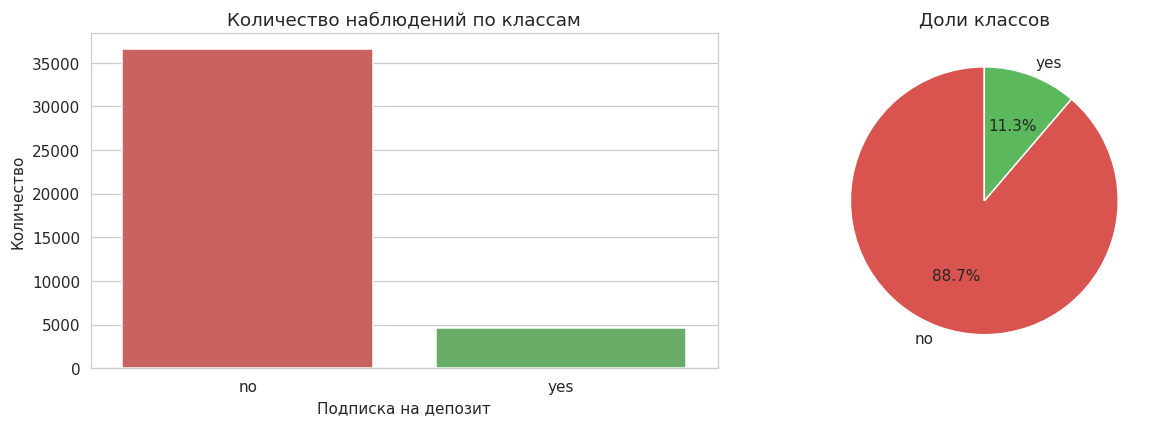

In [6]:
target_counts = df['y'].value_counts()
target_table = pd.DataFrame({
    'Класс': target_counts.index,
    'Количество': target_counts.values,
    'Доля, %': np.round(target_counts.values / len(df) * 100, 2),
})
print('Положительный класс: «да» (подписка на срочный депозит)')
display(target_table)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='y', ax=axes[0], palette=['#d9534f', '#5cb85c'])
axes[0].set_title('Количество наблюдений по классам')
axes[0].set_xlabel('Подписка на депозит')
axes[0].set_ylabel('Количество')

axes[1].pie(target_counts.values, labels=target_counts.index, autopct='%1.1f%%',
            colors=['#d9534f', '#5cb85c'], startangle=90)
axes[1].set_title('Доли классов')
plt.tight_layout()
plt.show()


### 4.4. Описательная статистика числовых признаков


In [7]:
numeric_raw = df.select_dtypes(include=np.number).columns.tolist()
display(df[numeric_raw].describe().T.round(2))


,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41176.0,258.32,259.31,0.00,102.00,180.00,319.00,4918.00
campaign,41176.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41176.0,962.46,186.94,0.00,999.00,999.00,999.00,999.00
previous,41176.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41176.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41176.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41176.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41176.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41176.0,5167.03,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


### 4.5. Проверка выбросов

Выбросы ищутся двумя способами: по правилу межквартильного размаха (IQR) — значения ниже $Q_1 - 1{,}5\cdot IQR$ или выше $Q_3 + 1{,}5\cdot IQR$, и по z-оценке $|z| > 3$. Анализ выполняется для числовых признаков, которые будут поданы в модель (`длительность_звонка` исключается как утечка).


,Q1,Q3,Нижняя граница,Верхняя граница,IQR: выбросов,"IQR, %",|z| > 3,"|z| > 3, %",Минимум,Максимум
Признак,,,,,,,,,,
age,32.00,47.00,9.50,69.50,468,1.14,369,0.90,17.00,98.00
campaign,1.00,3.00,-2.00,6.00,2406,5.84,869,2.11,1.00,56.00
pdays,999.00,999.00,999.00,999.00,1515,3.68,1515,3.68,0.00,999.00
previous,0.00,0.00,0.00,0.00,5625,13.66,1064,2.58,0.00,7.00
emp.var.rate,-1.80,1.40,-6.60,6.20,0,0.00,0,0.00,-3.40,1.40
cons.price.idx,93.08,93.99,91.70,95.37,0,0.00,0,0.00,92.20,94.77
cons.conf.idx,-42.70,-36.40,-52.15,-26.95,446,1.08,0,0.00,-50.80,-26.90
euribor3m,1.34,4.96,-4.08,10.39,0,0.00,0,0.00,0.63,5.04
nr.employed,5099.10,5228.10,4905.60,5421.60,0,0.00,0,0.00,4963.60,5228.10


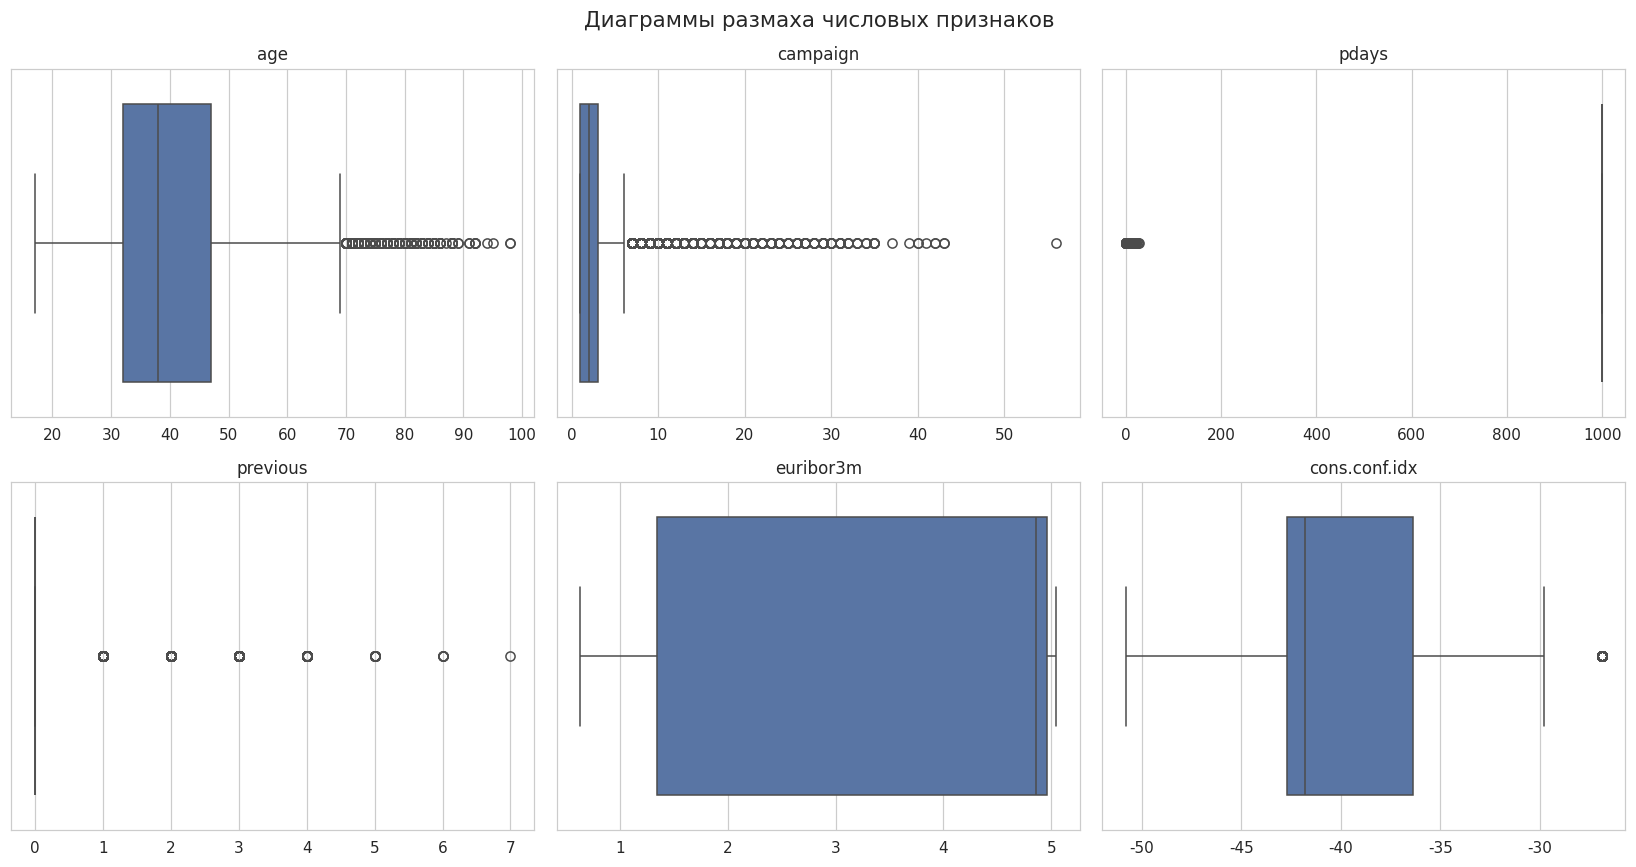

In [8]:
outlier_features = [c for c in df.select_dtypes(include=np.number).columns
                    if c != 'duration']

outlier_rows = []
for column in outlier_features:
    q1, q3 = df[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_iqr = int(((df[column] < lower) | (df[column] > upper)).sum())

    z_scores = (df[column] - df[column].mean()) / df[column].std()
    n_z = int((z_scores.abs() > 3).sum())

    outlier_rows.append({
        'Признак': column,
        'Q1': q1, 'Q3': q3,
        'Нижняя граница': lower, 'Верхняя граница': upper,
        'IQR: выбросов': n_iqr,
        'IQR, %': round(n_iqr / len(df) * 100, 2),
        '|z| > 3': n_z,
        '|z| > 3, %': round(n_z / len(df) * 100, 2),
        'Минимум': df[column].min(), 'Максимум': df[column].max(),
    })

outlier_table = pd.DataFrame(outlier_rows).set_index('Признак')
display(outlier_table.round(2))

plot_features = ['age', 'campaign', 'pdays',
                 'previous', 'euribor3m',
                 'cons.conf.idx']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.ravel(), plot_features):
    sns.boxplot(x=df[column], ax=ax, color='#4c72b0')
    ax.set_title(column, fontsize=11)
    ax.set_xlabel('')
plt.suptitle('Диаграммы размаха числовых признаков', fontsize=14)
plt.tight_layout()
plt.show()


**Интерпретация выбросов.** IQR и z-score выделяют необычные наблюдения, но не доказывают ошибку ввода. Специальный код `pdays=999` означает отсутствие прошлого контакта. В основном эксперименте наблюдения сохранены. Дополнительное сравнение вариантов проводится только на validation; тест не определяет выбор предобработки.

## 5. Исключение утечки целевой информации и формирование целевой переменной

Признак `длительность_звонка` (`duration`) **исключается**. Это классическая утечка целевой информации: длительность последнего звонка известна только после его завершения и напрямую связана с результатом — клиент, согласившийся на депозит, разговаривает существенно дольше. В документации UCI этот признак прямо рекомендуется удалять при построении реалистичной прогнозной модели. Если его оставить, метрики окажутся искусственно завышенными и неприменимыми на практике (в момент принятия решения о звонке длительность ещё неизвестна).

Других идентификаторов в наборе нет. Целевая переменная кодируется явно: `да` → 1 (положительный класс), `нет` → 0.

Дополнительно создаётся бинарный признак `ранее_не_контактировали (had_no_prior_contact)`: значение `pdays = 999` — это служебный код «клиента ранее не беспокоили», а не число дней. Индикатор добавляется к исходному pdays; служебный код 999 сохраняется как особенность выбранного представления.


In [9]:
# Исключение утечки
df = df.drop(columns=['duration'])

# Признак-индикатор специального кода pdays = 999
df['had_no_prior_contact'] = (df['pdays'] == 999).astype(int)

# Целевая переменная: 1 — подписка («да»), 0 — отказ («нет»)
y = (df['y'] == 'yes').astype(int)
X = df.drop(columns=['y'])

print('Размер X:', X.shape)
print('Распределение y:', dict(y.value_counts().sort_index()))
print('Доля положительного класса: %.2f %%' % (y.mean() * 100))
print('\nПризнаки, используемые моделью:')
print(list(X.columns))


Размер X: (41176, 20)
Распределение y: {0: np.int64(36537), 1: np.int64(4639)}
Доля положительного класса: 11.27 %

Признаки, используемые моделью:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'had_no_prior_contact']


## 6. Разделение данных на обучающую, валидационную и тестовую выборки

Разбиение выполняется **до** обучения параметров предобработки, чтобы избежать утечки данных. Используется стратифицированное разбиение 70 % / 15 % / 15 %: сначала выделяется train (70 %), затем оставшиеся 30 % поровну делятся на validation и test.


In [10]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

split_table = pd.DataFrame({
    'Выборка': ['Обучающая (train)', 'Валидационная (validation)', 'Тестовая (test)'],
    'Объектов': [len(X_train), len(X_val), len(X_test)],
    'Доля, %': [round(len(X_train) / len(X) * 100, 1),
                round(len(X_val) / len(X) * 100, 1),
                round(len(X_test) / len(X) * 100, 1)],
    'Положительный класс, %': [round(y_train.mean() * 100, 2),
                               round(y_val.mean() * 100, 2),
                               round(y_test.mean() * 100, 2)],
})
display(split_table)


,Выборка,Объектов,"Доля, %","Положительный класс, %"
0,Обучающая (train),28823,70.0,11.27
1,Валидационная (validation),6176,15.0,11.27
2,Тестовая (test),6177,15.0,11.27


## 7. Конвейер предобработки данных

Все параметры предобработки обучаются **только на обучающей выборке** и затем без повторного обучения применяются к валидационной и тестовой:

* **Числовые признаки** — заполнение пропусков медианой (медиана устойчива к выбросам), затем `StandardScaler` (приведение к нулевому среднему и единичной дисперсии).
* **Категориальные признаки** — заполнение наиболее частым значением, затем `OneHotEncoder` (с `handle_unknown='ignore'`, чтобы новые категории в тесте не приводили к ошибке).

Такая схема исключает утечку данных и обеспечивает корректное сравнение моделей.


In [11]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print(f'Числовых признаков: {len(numeric_features)}')
print(numeric_features)
print(f'\nКатегориальных признаков: {len(categorical_features)}')
print(categorical_features)

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features),
])

# Обучение параметров предобработки строго на train
X_train_prep = preprocessor.fit_transform(X_train).astype('float32')
X_val_prep = preprocessor.transform(X_val).astype('float32')
X_test_prep = preprocessor.transform(X_test).astype('float32')

feature_names = preprocessor.get_feature_names_out()
print(f'\nРазмерность после предобработки: {X_train_prep.shape[1]} признаков')
print('Примеры сформированных признаков:', list(feature_names[:5]), '...')

# --- Проверка обработки пропусков (параметры обучены только на train) ---
impute_report = pd.DataFrame({
    'Признак': categorical_features,
    'Пропусков в train': [int(X_train[c].isna().sum()) for c in categorical_features],
    'Заполняющее значение (мода)': [X_train[c].mode(dropna=True)[0] for c in categorical_features],
})
impute_report = impute_report[impute_report['Пропусков в train'] > 0]

print('Категориальные признаки, содержавшие пропуски:')
display(impute_report.set_index('Признак'))

print('Числовые признаки: пропусков в train =', int(X_train[numeric_features].isna().sum().sum()),
      '(медианное заполнение остаётся резервным)')
print('Пропусков (NaN) после предобработки:',
      f'train = {int(np.isnan(X_train_prep).sum())},',
      f'validation = {int(np.isnan(X_val_prep).sum())},',
      f'test = {int(np.isnan(X_test_prep).sum())}')
print('Всего заполнено значений:', int(impute_report['Пропусков в train'].sum()))


Числовых признаков: 10
['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'had_no_prior_contact']

Категориальных признаков: 10
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Размерность после предобработки: 57 признаков
Примеры сформированных признаков: ['numeric__age', 'numeric__campaign', 'numeric__pdays', 'numeric__previous', 'numeric__emp.var.rate'] ...
Категориальные признаки, содержавшие пропуски:
Числовые признаки: пропусков в train = 0 (медианное заполнение остаётся резервным)
Пропусков (NaN) после предобработки: train = 0, validation = 0, test = 0
Всего заполнено значений: 8858


,Пропусков в train,Заполняющее значение (мода)
Признак,,
job,242,admin.
marital,60,married
education,1221,university.degree
default,5963,no
housing,686,yes
loan,686,no


### 7.1. Дисбаланс классов и веса классов

Поскольку классы в обучающей выборке несбалансированы (88.7% «нет» против 11.3% «да»), при обучении модели задаются **веса классов**, обратно пропорциональные их частотам. Это повышает вклад редкого положительного класса в функцию потерь и улучшает Recall.

Формула: $w_c = \dfrac{N}{2 \cdot N_c}$, где $N$ — общее число объектов, $N_c$ — число объектов класса $c$.


In [12]:
n_samples = len(y_train)
n_negative = int((y_train == 0).sum())
n_positive = int((y_train == 1).sum())
CLASS_WEIGHT = {
    0: n_samples / (2 * n_negative),
    1: n_samples / (2 * n_positive),
}
print('Число объектов в train: отрицательных =', n_negative, ', положительных =', n_positive)
print('Веса классов:', {k: round(v, 3) for k, v in CLASS_WEIGHT.items()})


Число объектов в train: отрицательных = 25576 , положительных = 3247
Веса классов: {0: 0.563, 1: 4.438}


## 8. Исследуемые архитектуры MLP

Исследуется пять конфигураций. Они различаются существенными параметрами: числом скрытых слоёв и нейронов, функцией активации, оптимизатором и способом регуляризации. Сравнение показывает различия конфигураций, но не изолирует все факторы: часть параметров меняется одновременно.

| Модель | Скрытые слои | Активация | Dropout | L2 | Оптимизатор | Learning rate | Batch size | Max эпох |
|---|---|---|---|---|---|---|---|---|
| MLP-1 (компактная) | 32 | ReLU | — | — | Adam | 0,001 | 256 | 60 |
| MLP-2 (средняя) | 64 → 32 | ReLU | 0,30 | — | Adam | 0,001 | 256 | 60 |
| MLP-3 (глубокая) | 128 → 64 → 32 | ReLU | 0,30 | 1e-4 | Adam | 0,001 | 256 | 60 |
| MLP-4 (tanh) | 64 → 32 | tanh | 0,30 | — | Adam | 0,001 | 256 | 60 |
| MLP-5 (RMSprop) | 64 → 32 | ReLU | 0,30 | — | RMSprop | 0,001 | 256 | 60 |

Общие условия обучения для всех моделей:

* функция потерь — **бинарная кросс-энтропия** (`binary_crossentropy`);
* выходной слой — один нейрон с активацией **sigmoid** (вероятность положительного класса);
* критерий остановки — **EarlyStopping** по `val_loss` (patience = 8, восстановление лучших весов);
* веса классов передаются в `fit` для компенсации дисбаланса.

MLP-1 показывает базовый уровень без регуляризации, MLP-2 добавляет Dropout, MLP-3 — более глубокую и широкую сеть с L2-регуляризацией, MLP-4 проверяет влияние активации `tanh`, MLP-5 — влияние альтернативного оптимизатора RMSprop.


In [13]:
def build_mlp(input_dim, hidden_layers, activation='relu', dropout=0.0, l2=0.0,
              optimizer_name='adam', learning_rate=1e-3, seed=SEED):
    # Создание полносвязной сети для бинарной классификации
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    regularizer = tf.keras.regularizers.l2(l2) if l2 > 0 else None
    layers = [tf.keras.layers.Input(shape=(input_dim,))]
    for units in hidden_layers:
        layers.append(tf.keras.layers.Dense(units, activation=activation,
                                            kernel_regularizer=regularizer))
        if dropout > 0:
            layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(1, activation='sigmoid'))
    model = tf.keras.Sequential(layers)

    if optimizer_name == 'adam':
        optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    elif optimizer_name == 'rmsprop':
        optimizer = tf.keras.optimizers.RMSprop(learning_rate=learning_rate)
    elif optimizer_name == 'sgd':
        optimizer = tf.keras.optimizers.SGD(learning_rate=learning_rate,
                                            momentum=0.9, nesterov=True)
    else:
        raise ValueError(f'Неизвестный оптимизатор: {optimizer_name}')

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=[tf.keras.metrics.AUC(name='auc')],
    )
    return model


def calc_metrics(y_true, y_proba, threshold=0.5):
    # Метрики бинарной классификации по вероятностям
    y_pred = (np.asarray(y_proba) >= threshold).astype(int)
    y_true = np.asarray(y_true)
    auc = roc_auc_score(y_true, y_proba) if len(np.unique(y_proba)) > 1 else 0.5
    return {
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_true, y_pred),
        'F1-score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': auc,
    }


def get_proba(model, X):
    return model.predict(X, verbose=0).ravel()


def dataset(X, y=None, batch_size=256, training=False, weights=None):
    X = np.asarray(X, dtype='float32')
    if y is None:
        ds = tf.data.Dataset.from_tensor_slices(X)
    else:
        y = np.asarray(y, dtype='float32')
        if weights is None:
            ds = tf.data.Dataset.from_tensor_slices((X, y))
        else:
            w = np.array([weights[int(v)] for v in y], dtype='float32')
            ds = tf.data.Dataset.from_tensor_slices((X, y, w))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    options.threading.max_intra_op_parallelism = 1
    return ds.batch(batch_size).with_options(options)

def get_proba(model, X):
    return model.predict(dataset(X), verbose=0).ravel()


In [14]:
CONFIGS = {
    'MLP-1 (компактная)': dict(
        hidden_layers=[32], activation='relu', dropout=0.0, l2=0.0,
        optimizer_name='adam', learning_rate=1e-3),
    'MLP-2 (средняя)': dict(
        hidden_layers=[64, 32], activation='relu', dropout=0.3, l2=0.0,
        optimizer_name='adam', learning_rate=1e-3),
    'MLP-3 (глубокая)': dict(
        hidden_layers=[128, 64, 32], activation='relu', dropout=0.3, l2=1e-4,
        optimizer_name='adam', learning_rate=1e-3),
    'MLP-4 (tanh)': dict(
        hidden_layers=[64, 32], activation='tanh', dropout=0.3, l2=0.0,
        optimizer_name='adam', learning_rate=1e-3),
    'MLP-5 (RMSprop)': dict(
        hidden_layers=[64, 32], activation='relu', dropout=0.3, l2=0.0,
        optimizer_name='rmsprop', learning_rate=1e-3),
}

BATCH_SIZE = 256
MAX_EPOCHS = 60

for name, cfg in CONFIGS.items():
    cfg['batch_size'] = BATCH_SIZE
    cfg['epochs'] = MAX_EPOCHS

display(pd.DataFrame([
    {'Модель': name,
     'Скрытые слои': ' → '.join(map(str, cfg['hidden_layers'])),
     'Активация': cfg['activation'],
     'Dropout': cfg['dropout'],
     'L2': cfg['l2'],
     'Оптимизатор': cfg['optimizer_name'],
     'LR': cfg['learning_rate'],
     'Batch': cfg['batch_size'],
     'Max эпох': cfg['epochs']}
    for name, cfg in CONFIGS.items()
]))

,Модель,Скрытые слои,Активация,Dropout,L2,Оптимизатор,LR,Batch,Max эпох
0,MLP-1 (компактная),32,relu,0.0,0.0000,adam,0.001,256,60
1,MLP-2 (средняя),64 → 32,relu,0.3,0.0000,adam,0.001,256,60
2,MLP-3 (глубокая),128 → 64 → 32,relu,0.3,0.0001,adam,0.001,256,60
3,MLP-4 (tanh),64 → 32,tanh,0.3,0.0000,adam,0.001,256,60
4,MLP-5 (RMSprop),64 → 32,relu,0.3,0.0000,rmsprop,0.001,256,60


## 9. Обучение моделей

Каждая модель обучается на одной и той же обучающей выборке при одинаковых условиях (кроме исследуемого параметра). Контроль качества — по валидационной выборке. Тестовая выборка на этом этапе **не используется**.


In [15]:
models = {}
histories = {}
training_info = {}

for name, cfg in CONFIGS.items():
    model = build_mlp(
        input_dim=X_train_prep.shape[1],
        hidden_layers=cfg['hidden_layers'],
        activation=cfg['activation'],
        dropout=cfg['dropout'],
        l2=cfg['l2'],
        optimizer_name=cfg['optimizer_name'],
        learning_rate=cfg['learning_rate'],
    )
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=8, min_delta=1e-4,
        restore_best_weights=True, verbose=0,
    )

    start = time.time()
    history = model.fit(
        dataset(X_train_prep, y_train, cfg['batch_size'], training=True, weights=CLASS_WEIGHT),
        validation_data=dataset(X_val_prep, y_val),
        epochs=cfg['epochs'],
        callbacks=[early_stopping],
        shuffle=False,  # Перемешивание уже выполняется в dataset().
        verbose=0,
    )
    elapsed = time.time() - start

    best_epoch = int(np.argmin(history.history['val_loss'])) + 1
    models[name] = model
    histories[name] = history
    training_info[name] = {
        'Эпох обучено': len(history.history['loss']),
        'Лучшая эпоха': best_epoch,
        'Время, с': round(elapsed, 1),
        'Лучший val_loss': round(float(np.min(history.history['val_loss'])), 4),
    }
    print(f"{name}: эпох = {len(history.history['loss'])}, "
          f"лучшая эпоха = {best_epoch}, "
          f"val_loss = {np.min(history.history['val_loss']):.4f}, "
          f"время = {elapsed:.1f} с")

display(pd.DataFrame(training_info).T)


MLP-1 (компактная): эпох = 29, лучшая эпоха = 21, val_loss = 0.4807, время = 7.6 с
MLP-2 (средняя): эпох = 29, лучшая эпоха = 21, val_loss = 0.4907, время = 7.2 с
MLP-3 (глубокая): эпох = 32, лучшая эпоха = 24, val_loss = 0.4775, время = 10.7 с
MLP-4 (tanh): эпох = 9, лучшая эпоха = 1, val_loss = 0.4847, время = 3.0 с
MLP-5 (RMSprop): эпох = 22, лучшая эпоха = 14, val_loss = 0.5006, время = 5.7 с


,Эпох обучено,Лучшая эпоха,"Время, с",Лучший val_loss
MLP-1 (компактная),29.0,21.0,7.6,0.4807
MLP-2 (средняя),29.0,21.0,7.2,0.4907
MLP-3 (глубокая),32.0,24.0,10.7,0.4775
MLP-4 (tanh),9.0,1.0,3.0,0.4847
MLP-5 (RMSprop),22.0,14.0,5.7,0.5006


## 10. Графики обучения

По графикам видно, как изменяются потери на обучающей и валидационной выборках. Признак переобучения — расхождение кривых: training loss продолжает снижаться, а validation loss начинает расти. EarlyStopping возвращает модель к эпохе с минимальным `val_loss`.


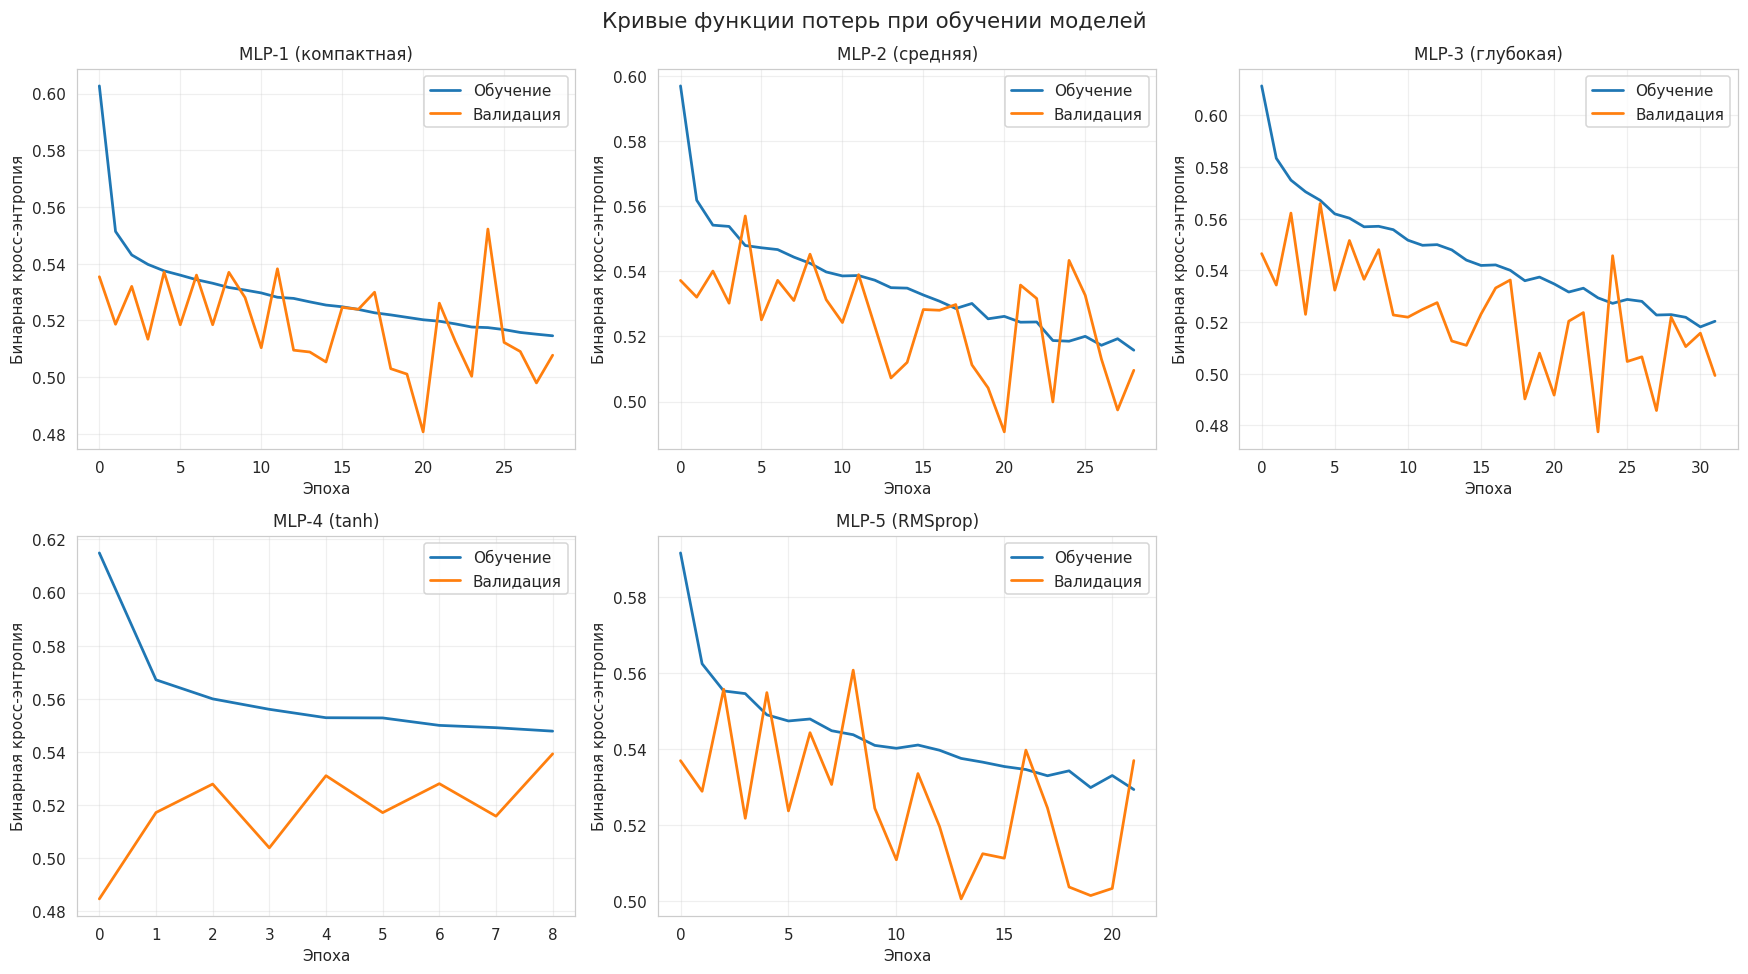

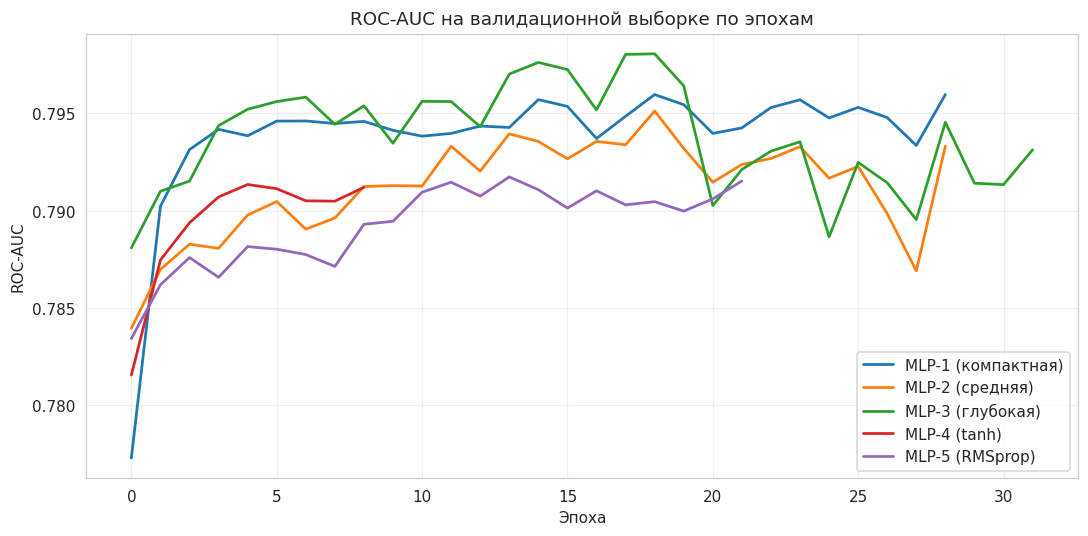

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()
for ax, (name, history) in zip(axes, histories.items()):
    ax.plot(history.history['loss'], label='Обучение', linewidth=1.8)
    ax.plot(history.history['val_loss'], label='Валидация', linewidth=1.8)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel('Эпоха')
    ax.set_ylabel('Бинарная кросс-энтропия')
    ax.legend()
    ax.grid(alpha=0.3)
axes[-1].axis('off')
fig.suptitle('Кривые функции потерь при обучении моделей', fontsize=14)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
for name, history in histories.items():
    ax.plot(history.history['val_auc'], label=name, linewidth=1.8)
ax.set_title('ROC-AUC на валидационной выборке по эпохам')
ax.set_xlabel('Эпоха')
ax.set_ylabel('ROC-AUC')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 11. Сравнение моделей на валидационной выборке

Порог классификации на этом этапе — стандартный 0,5. ROC-AUC не зависит от порога и характеризует способность модели ранжировать объекты.


,Recall,Precision,Balanced Accuracy,F1-score,ROC-AUC
Модель,,,,,
MLP-1 (компактная),0.622,0.389,0.749,0.478,0.794
MLP-3 (глубокая),0.631,0.385,0.752,0.478,0.794
MLP-5 (RMSprop),0.599,0.402,0.743,0.481,0.792
MLP-2 (средняя),0.635,0.386,0.753,0.480,0.792
MLP-4 (tanh),0.639,0.352,0.745,0.454,0.782


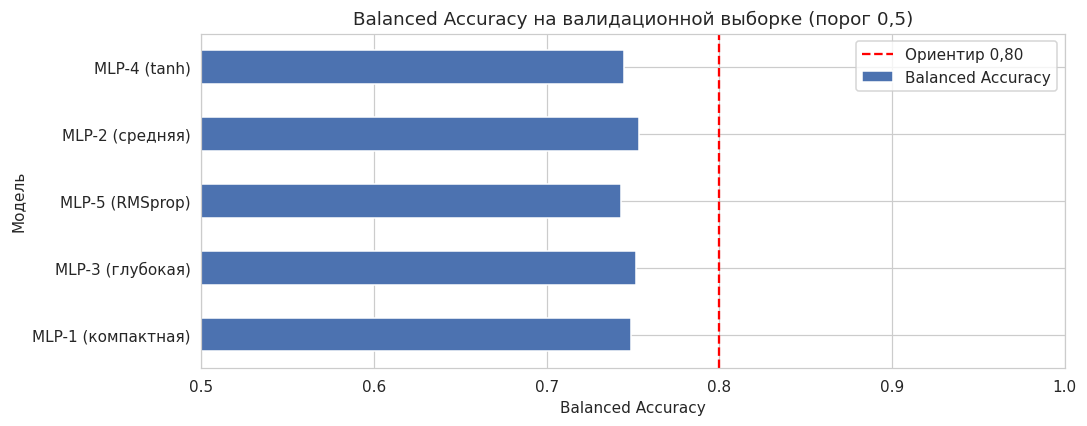

In [17]:
val_rows = []
for name, model in models.items():
    proba = get_proba(model, X_val_prep)
    metrics = calc_metrics(y_val, proba, threshold=0.5)
    val_rows.append({'Модель': name, **metrics})

val_results = pd.DataFrame(val_rows).set_index('Модель')
val_results = val_results.sort_values('ROC-AUC', ascending=False)
display(val_results.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
val_results['Balanced Accuracy'].plot(kind='barh', ax=ax, color='#4c72b0')
ax.axvline(0.8, color='red', linestyle='--', label='Ориентир 0,80')
ax.set_xlim(0.5, 1.0)
ax.set_title('Balanced Accuracy на валидационной выборке (порог 0,5)')
ax.set_xlabel('Balanced Accuracy')
ax.legend()
plt.tight_layout()
plt.show()


## 12. Базовая модель (DummyClassifier)

Для корректного сравнения обучаются две базовые модели: `most_frequent` (всегда предсказывает мажоритарный класс «нет») и `prior` (всегда возвращает априорную вероятность положительного класса). Базовая модель показывает уровень «наивного» прогноза, который должна превзойти нейронная сеть.


In [18]:
baseline_rows = []
for strategy in ['most_frequent', 'prior']:
    dummy = DummyClassifier(strategy=strategy, random_state=SEED)
    dummy.fit(X_train_prep, y_train)
    proba = dummy.predict_proba(X_val_prep)[:, 1]
    metrics = calc_metrics(y_val, proba, threshold=0.5)
    baseline_rows.append({'Модель': f'Dummy ({strategy})', **metrics})

baseline_val = pd.DataFrame(baseline_rows).set_index('Модель')
display(baseline_val.round(3))

print('Dummy (most_frequent) предсказывает только класс 0, поэтому Recall = 0,')
print('а Balanced Accuracy = 0,5 — это уровень случайного угадывания для двух классов.')


Dummy (most_frequent) предсказывает только класс 0, поэтому Recall = 0,
а Balanced Accuracy = 0,5 — это уровень случайного угадывания для двух классов.


,Recall,Precision,Balanced Accuracy,F1-score,ROC-AUC
Модель,,,,,
Dummy (most_frequent),0.0,0.0,0.5,0.0,0.5
Dummy (prior),0.0,0.0,0.5,0.0,0.5


## 13. Выбор лучшей модели и подбор порога классификации

Лучшая модель выбирается по **ROC-AUC на валидационной выборке** (метрика не зависит от порога и устойчива к дисбалансу). Дополнительно для лучшей модели подбирается порог вероятности: при сильном дисбалансе порог 0,5 не оптимален, и его смещение позволяет сбалансировать Recall и Precision. Порог подбирается **только на валидационной выборке** по максимуму Balanced Accuracy; тестовая выборка для этого не используется.

Лучшая модель по ROC-AUC на валидации: MLP-1 (компактная)
Её метрики на валидации (порог 0,5):
Оптимальный порог на валидации: 0.52
Метрики лучшей модели на валидации при подобранном пороге:


Recall               0.622
Precision            0.389
Balanced Accuracy    0.749
F1-score             0.478
ROC-AUC              0.794
dtype: float64

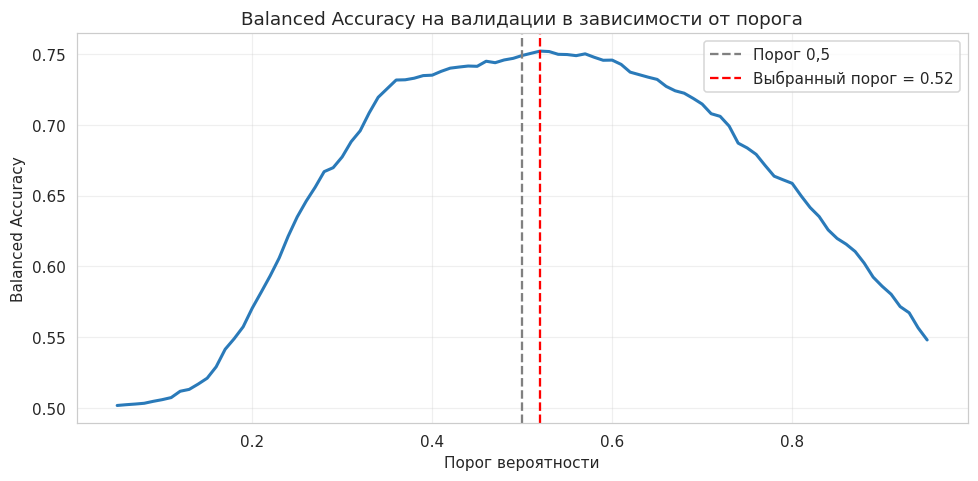

Recall               0.621
Precision            0.403
Balanced Accuracy    0.752
F1-score             0.489
ROC-AUC              0.794
dtype: float64

In [19]:
best_model_name = val_results.index[0]
best_model = models[best_model_name]
print('Лучшая модель по ROC-AUC на валидации:', best_model_name)
print('Её метрики на валидации (порог 0,5):')
display(pd.Series(calc_metrics(y_val, get_proba(best_model, X_val_prep))).round(3))

best_val_proba = get_proba(best_model, X_val_prep)
thresholds = np.arange(0.05, 0.96, 0.01)
balanced_scores = [balanced_accuracy_score(y_val, (best_val_proba >= t).astype(int))
                   for t in thresholds]
best_threshold = float(thresholds[int(np.argmax(balanced_scores))])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(thresholds, balanced_scores, color='#2a7ab9', linewidth=2)
ax.axvline(0.5, color='grey', linestyle='--', label='Порог 0,5')
ax.axvline(best_threshold, color='red', linestyle='--',
           label=f'Выбранный порог = {best_threshold:.2f}')
ax.set_title('Balanced Accuracy на валидации в зависимости от порога')
ax.set_xlabel('Порог вероятности')
ax.set_ylabel('Balanced Accuracy')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Оптимальный порог на валидации: {best_threshold:.2f}')
print('Метрики лучшей модели на валидации при подобранном пороге:')
display(pd.Series(calc_metrics(y_val, best_val_proba, threshold=best_threshold)).round(3))


## Анализ переобучения
Сравниваем AUC и невзвешенную кросс-энтропию на train и validation у сохранённых моделей. Для этих оценок Dropout отключён. Кривые истории обучения имеют другой смысл: training loss рассчитан с весами классов и активным Dropout, а validation loss — без весов классов. Их абсолютные уровни нельзя напрямую трактовать как величину переобучения.

In [20]:
overfit_rows = []
for name, model in models.items():
    train_loss, train_auc = model.evaluate(dataset(X_train_prep, y_train), verbose=0)
    val_loss, val_auc = model.evaluate(dataset(X_val_prep, y_val), verbose=0)
    overfit_rows.append({
        'Модель': name,
        'train_loss': train_loss,
        'val_loss': val_loss,
        'Разрыв loss': val_loss - train_loss,
        'train_AUC': train_auc,
        'val_AUC': val_auc,
        'Разрыв AUC': train_auc - val_auc,
        'Эпох': training_info[name]['Эпох обучено'],
    })

overfit_table = pd.DataFrame(overfit_rows).set_index('Модель')
display(overfit_table.round(4))


,train_loss,val_loss,Разрыв loss,train_AUC,val_AUC,Разрыв AUC,Эпох
Модель,,,,,,,
MLP-1 (компактная),0.4725,0.4807,0.0082,0.8168,0.7940,0.0228,29
MLP-2 (средняя),0.4801,0.4907,0.0105,0.8257,0.7915,0.0342,29
MLP-3 (глубокая),0.4591,0.4775,0.0183,0.8381,0.7935,0.0446,32
MLP-4 (tanh),0.4856,0.4847,-0.0009,0.7805,0.7816,-0.0011,9
MLP-5 (RMSprop),0.4959,0.5006,0.0047,0.8089,0.7917,0.0172,22


## Дополнительный эксперимент с выбросами
Сравним одну архитектуру 64 → 32, ReLU, Dropout 0,3 на трёх вариантах подготовки данных. Границы обрезки и z-score определяются по train. Для каждого варианта заново обучаем предобработку на его train и применяем её к соответствующей validation. Веса классов пересчитываются после удаления строк. Основное сравнение архитектур использует исходный конвейер без удаления выбросов.

In [21]:
# Все варианты оцениваются на validation; тест здесь не используется.
def fit_variant(X_tr, y_tr, X_va, label):
    model = build_mlp(X_tr.shape[1], [64, 32], dropout=0.3)
    y_tr_array = np.asarray(y_tr)
    weights = {k: len(y_tr_array)/(2*np.sum(y_tr_array == k)) for k in [0,1]}
    model.fit(dataset(X_tr, y_tr, training=True, weights=weights),
        validation_data=dataset(X_va, y_val), epochs=60, verbose=0, shuffle=False,
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8,
            min_delta=1e-4, restore_best_weights=True)])
    return {'Вариант':label, **calc_metrics(y_val, get_proba(model, X_va))}

from sklearn.base import clone
variant_rows = []
variant_rows.append(fit_variant(X_train_prep, y_train, X_val_prep, 'Без обрезки'))
low, high = X_train[numeric_features].quantile(.01), X_train[numeric_features].quantile(.99)
X_train_clip, X_val_clip = X_train.copy(), X_val.copy()
for col in numeric_features:
    X_train_clip[col] = X_train_clip[col].clip(low[col],high[col])
    X_val_clip[col] = X_val_clip[col].clip(low[col],high[col])
clip_preprocessor = clone(preprocessor)
variant_rows.append(fit_variant(clip_preprocessor.fit_transform(X_train_clip), y_train,
    clip_preprocessor.transform(X_val_clip), 'Обрезка 1–99 %'))
z = (X_train[numeric_features]-X_train[numeric_features].mean())/X_train[numeric_features].std().replace(0,1)
keep = (z.abs() <= 3).all(axis=1)
trim_preprocessor = clone(preprocessor)
variant_rows.append(fit_variant(trim_preprocessor.fit_transform(X_train.loc[keep]), y_train.loc[keep],
    trim_preprocessor.transform(X_val), 'Удаление |z| > 3'))
outlier_experiment = pd.DataFrame(variant_rows).set_index('Вариант')
display(outlier_experiment.round(3))
print('Это дополнительный анализ на validation; основной заранее заданный конвейер сохраняется.')


Это дополнительный анализ на validation; основной заранее заданный конвейер сохраняется.


,Recall,Precision,Balanced Accuracy,F1-score,ROC-AUC
Вариант,,,,,
Без обрезки,0.635,0.386,0.753,0.480,0.792
Обрезка 1–99 %,0.635,0.381,0.752,0.476,0.792
Удаление |z| > 3,0.501,0.218,0.636,0.303,0.602


**Интерпретация.** Таблица показывает влияние обработки на валидационную выборку в одном запуске. Более высокий AUC означает лучшее ранжирование на этой выборке. Без повторных разбиений нельзя утверждать статистическую значимость различий. Отдельные экстремальные значения не удаляются автоматически из основного эксперимента.

## Компромисс Recall–Precision на validation
Рабочий порог основной модели выбирается по максимуму Balanced Accuracy на validation. Дополнительно исследуем пороги для Recall ≥ 0,80 и Precision ≥ 0,80 на этой же выборке. Тестовые метки для поиска порогов не используются. Average Precision — отдельная сводная метрика PR-кривой; её не следует смешивать с ROC-AUC.

Average Precision = 0.454
Чтобы получить Recall >= 0,80: порог = 0.306, Recall = 0.800, Precision = 0.190, Balanced Accuracy = 0.684
Чтобы получить Precision >= 0,80: порог = 0.950, Recall = 0.099, Precision = 0.802, Balanced Accuracy = 0.548


,Recall,Precision,Balanced Accuracy,F1-score
Порог,,,,
0.1,1.000,0.114,0.506,0.204
0.2,0.938,0.130,0.570,0.228
0.3,0.805,0.185,0.677,0.301
0.4,0.682,0.290,0.735,0.407
0.5,0.622,0.389,0.749,0.478
0.6,0.585,0.443,0.746,0.504
0.7,0.497,0.482,0.715,0.489
0.8,0.358,0.529,0.659,0.427
0.9,0.184,0.660,0.586,0.288


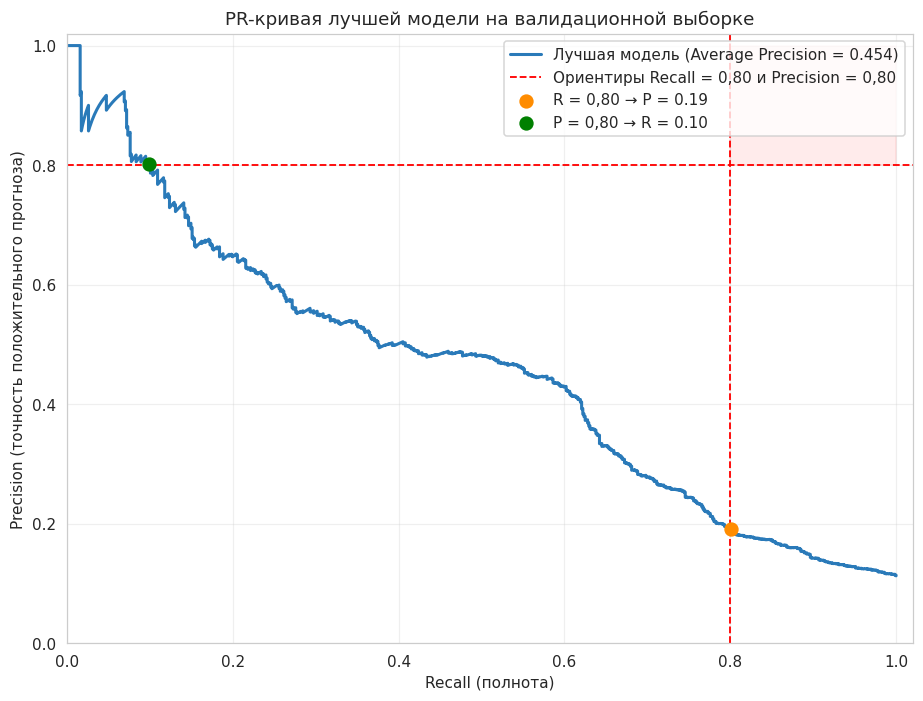

In [22]:
# PR-кривая лучшей модели на валидационной выборке
precision_curve, recall_curve, pr_thresholds = precision_recall_curve(y_val, best_val_proba)
average_precision = average_precision_score(y_val, best_val_proba)

# Точки, соответствующие разным порогам
threshold_rows = []
for t in np.arange(0.1, 0.91, 0.1):
    pred = (best_val_proba >= t).astype(int)
    threshold_rows.append({
        'Порог': round(float(t), 1),
        'Recall': recall_score(y_val, pred),
        'Precision': precision_score(y_val, pred, zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_val, pred),
        'F1-score': f1_score(y_val, pred, zero_division=0),
    })
threshold_table = pd.DataFrame(threshold_rows).set_index('Порог')
display(threshold_table.round(3))

# Наибольший порог с Recall >= 0,80; Precision не обязана быть монотонной
r80 = None
for t in np.arange(0.999, 0.0, -0.001):
    pred = (best_val_proba >= t).astype(int)
    if recall_score(y_val, pred) >= 0.80:
        r80 = (float(t), recall_score(y_val, pred),
               precision_score(y_val, pred, zero_division=0),
               balanced_accuracy_score(y_val, pred))
        break

# Порог, при котором Precision >= 0,80 (максимальный Recall среди таких точек)
p80 = None
for t in np.arange(0.05, 0.999, 0.001):
    pred = (best_val_proba >= t).astype(int)
    if precision_score(y_val, pred, zero_division=0) >= 0.80:
        p80 = (float(t), recall_score(y_val, pred),
               precision_score(y_val, pred, zero_division=0),
               balanced_accuracy_score(y_val, pred))
        break

print(f'Average Precision = {average_precision:.3f}')
if r80:
    print(f'Чтобы получить Recall >= 0,80: порог = {r80[0]:.3f}, '
          f'Recall = {r80[1]:.3f}, Precision = {r80[2]:.3f}, Balanced Accuracy = {r80[3]:.3f}')
if p80:
    print(f'Чтобы получить Precision >= 0,80: порог = {p80[0]:.3f}, '
          f'Recall = {p80[1]:.3f}, Precision = {p80[2]:.3f}, Balanced Accuracy = {p80[3]:.3f}')

fig, ax = plt.subplots(figsize=(8.5, 6.5))
ax.plot(recall_curve, precision_curve, color='#2a7ab9', linewidth=2,
        label=f'Лучшая модель (Average Precision = {average_precision:.3f})')
ax.axhline(0.8, color='red', linestyle='--', linewidth=1.2)
ax.axvline(0.8, color='red', linestyle='--', linewidth=1.2,
           label='Ориентиры Recall = 0,80 и Precision = 0,80')
ax.fill_between([0.8, 1.0], 0.8, 1.0, color='red', alpha=0.08)
if r80:
    ax.scatter([r80[1]], [r80[2]], color='darkorange', s=70, zorder=5,
               label=f'R = 0,80 → P = {r80[2]:.2f}')
if p80:
    ax.scatter([p80[1]], [p80[2]], color='green', s=70, zorder=5,
               label=f'P = 0,80 → R = {p80[1]:.2f}')
ax.set_title('PR-кривая лучшей модели на валидационной выборке')
ax.set_xlabel('Recall (полнота)')
ax.set_ylabel('Precision (точность положительного прогноза)')
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.legend(loc='upper right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Интерпретация.** Снижение порога обычно увеличивает Recall и количество ложных срабатываний. Значения выше относятся к validation. Порог, найденный по ограничению Precision или Recall, не гарантирует такой же показатель на новых данных. Вывод ограничен исследованной моделью и этим разбиением.

In [23]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Сильная модель другого класса на тех же предобработанных признаках
hgb = HistGradientBoostingClassifier(
    max_iter=300, learning_rate=0.05, class_weight='balanced', random_state=SEED
)
hgb.fit(X_train_prep, y_train)

hgb_proba_val = hgb.predict_proba(X_val_prep)[:, 1]

# Порог выбирается по валидационной выборке, как и для нейронных сетей
hgb_thresholds = np.arange(0.05, 0.96, 0.005)
hgb_ba = [balanced_accuracy_score(y_val, (hgb_proba_val >= t).astype(int))
          for t in hgb_thresholds]
hgb_threshold = float(hgb_thresholds[int(np.argmax(hgb_ba))])

print('Порог бустинга по validation:', round(hgb_threshold,3))


Порог бустинга по validation: 0.435


## Ограничения сравнения
Бустинг служит дополнительной моделью на тех же признаках. Близкие результаты нескольких моделей не доказывают предел качества данных. Достижимость рекомендуемых ориентиров зависит от представления признаков, настроек и способа проверки. Выводы распространяются только на проведённые эксперименты.

## Итоговая оценка на test
Архитектуры, предобработка и пороги зафиксированы до этого этапа. Вычисляем метрики всех исследованных моделей на одинаковых тестовых объектах; тестовый лидер не изменяет выбор по validation.

In [24]:
test_rows = []
for name, model in models.items():
    metrics = calc_metrics(y_test, get_proba(model, X_test_prep), threshold=0.5)
    test_rows.append({'Модель': name, **metrics})

for strategy in ['most_frequent', 'prior']:
    dummy = DummyClassifier(strategy=strategy, random_state=SEED).fit(X_train_prep, y_train)
    metrics = calc_metrics(y_test, dummy.predict_proba(X_test_prep)[:, 1], threshold=0.5)
    test_rows.append({'Модель': f'Dummy ({strategy})', **metrics})

test_results = pd.DataFrame(test_rows).set_index('Модель')

# Лучшая модель при подобранном пороге
best_test_proba = get_proba(best_model, X_test_prep)
test_results.loc[f'{best_model_name} (порог {best_threshold:.2f})'] = \
    pd.Series(calc_metrics(y_test, best_test_proba, threshold=best_threshold))

display(test_results.round(3))


,Recall,Precision,Balanced Accuracy,F1-score,ROC-AUC
Модель,,,,,
MLP-1 (компактная),0.647,0.414,0.765,0.505,0.815
MLP-2 (средняя),0.649,0.406,0.764,0.500,0.810
MLP-3 (глубокая),0.642,0.415,0.764,0.505,0.811
MLP-4 (tanh),0.651,0.374,0.756,0.475,0.804
MLP-5 (RMSprop),0.622,0.423,0.757,0.503,0.815
Dummy (most_frequent),0.000,0.000,0.500,0.000,0.500
Dummy (prior),0.000,0.000,0.500,0.000,0.500
MLP-1 (компактная) (порог 0.52),0.635,0.425,0.763,0.509,0.815


TN = 4882, FP = 599, FN = 254, TP = 442
Пропущено положительных объектов (FN): 254 из 696


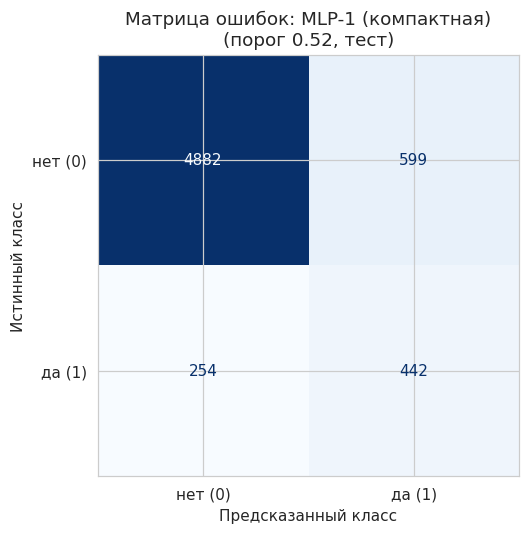

In [25]:
# Матрица ошибок лучшей модели при подобранном пороге
y_pred_best = (best_test_proba >= best_threshold).astype(int)
cm = confusion_matrix(y_test, y_pred_best)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=['нет (0)', 'да (1)']).plot(
    ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title(f'Матрица ошибок: {best_model_name}\n(порог {best_threshold:.2f}, тест)')
ax.set_xlabel('Предсказанный класс')
ax.set_ylabel('Истинный класс')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}')
print(f'Пропущено положительных объектов (FN): {fn} из {fn + tp}')


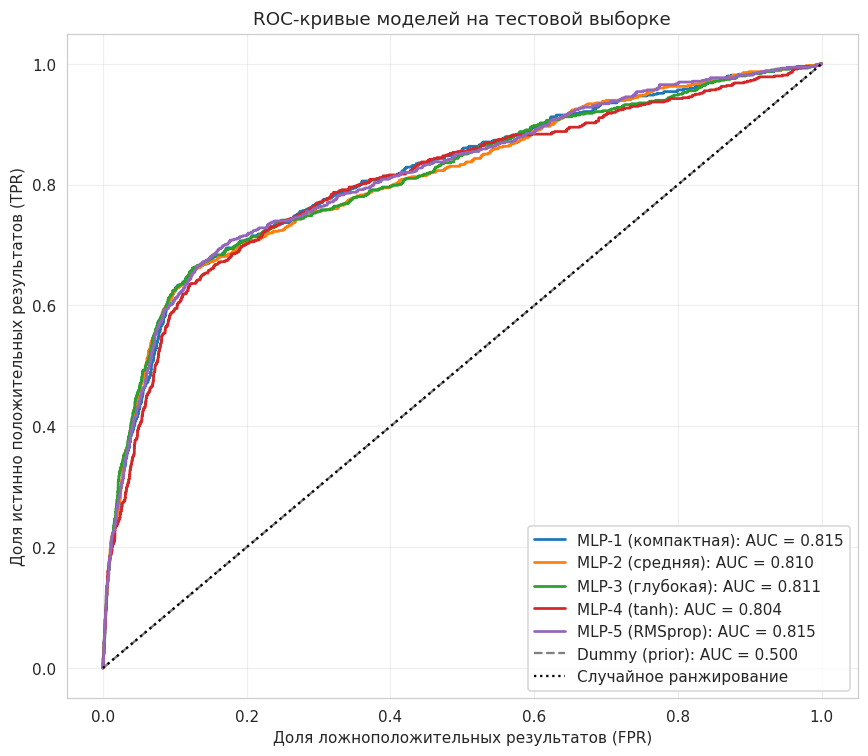

In [26]:
# ROC-кривые всех моделей на тестовой выборке
fig, ax = plt.subplots(figsize=(8, 7))
for name, model in models.items():
    proba = get_proba(model, X_test_prep)
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, linewidth=1.8, label=f'{name}: AUC = {auc:.3f}')

dummy = DummyClassifier(strategy='prior', random_state=SEED).fit(X_train_prep, y_train)
dummy_proba = dummy.predict_proba(X_test_prep)[:, 1]
fpr, tpr, _ = roc_curve(y_test, dummy_proba)
ax.plot(fpr, tpr, linestyle='--', color='grey',
        label=f'Dummy (prior): AUC = {roc_auc_score(y_test, dummy_proba):.3f}')

ax.plot([0, 1], [0, 1], linestyle=':', color='black', label='Случайное ранжирование')
ax.set_title('ROC-кривые моделей на тестовой выборке')
ax.set_xlabel('Доля ложноположительных результатов (FPR)')
ax.set_ylabel('Доля истинно положительных результатов (TPR)')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [27]:
print(f'Отчёт по классам для лучшей модели: {best_model_name} '
      f'(порог {best_threshold:.2f}, тест)\n')
print(classification_report(y_test, y_pred_best,
                            target_names=['нет (0)', 'да (1)'], digits=3))


Отчёт по классам для лучшей модели: MLP-1 (компактная) (порог 0.52, тест)

              precision    recall  f1-score   support

     нет (0)      0.951     0.891     0.920      5481
      да (1)      0.425     0.635     0.509       696

    accuracy                          0.862      6177
   macro avg      0.688     0.763     0.714      6177
weighted avg      0.891     0.862     0.873      6177



## Итоговые выводы
Числа ниже рассчитываются из текущего запуска. Модель и основной порог выбраны по validation. Все архитектуры и базовые модели оцениваются на одинаковом test; его результаты не используются для пересмотра выбора.

In [28]:
hgb_proba_test = hgb.predict_proba(X_test_prep)[:, 1]
comparison = pd.DataFrame({
    'Выбранная MLP':calc_metrics(y_test,best_test_proba,best_threshold),
    'HistGradientBoosting':calc_metrics(y_test,hgb_proba_test,hgb_threshold)}).T
display(comparison.round(3))
print('Выбранная модель:', best_model_name)
print('Рабочий порог:', round(best_threshold,2))
print('Признаков после обработки:', X_train_prep.shape[1])
print('Эпох обучения:', training_info[best_model_name]['Эпох обучено'])
print('Число параметров:', best_model.count_params())
print('Разрыв train-val AUC:', round(overfit_table.loc[best_model_name,'Разрыв AUC'],4))
print('Метрики MLP на тесте:')
display(pd.Series(calc_metrics(y_test,best_test_proba,best_threshold)).round(4))
print('Результаты относятся к одному разбиению. Предел качества данных не установлен.')


Выбранная модель: MLP-1 (компактная)
Рабочий порог: 0.52
Признаков после обработки: 57
Эпох обучения: 29
Число параметров: 1889
Разрыв train-val AUC: 0.0228
Метрики MLP на тесте:
Результаты относятся к одному разбиению. Предел качества данных не установлен.


,Recall,Precision,Balanced Accuracy,F1-score,ROC-AUC
Выбранная MLP,0.635,0.425,0.763,0.509,0.815
HistGradientBoosting,0.681,0.347,0.759,0.460,0.823


Recall               0.6351
Precision            0.4246
Balanced Accuracy    0.7629
F1-score             0.5089
ROC-AUC              0.8146
dtype: float64

## Ограничения и улучшения
Использовано одно стратифицированное разбиение; доверительные интервалы и повторная кросс-валидация не рассчитаны. Качество и ранжирование моделей могут измениться при другом seed или окружении. Редкий положительный класс затрудняет одновременное повышение Precision и Recall. Возможные улучшения: подбор параметров по validation, повторные разбиения и дополнительные признаки, доступные до звонка. Ориентиры 0,80 рекомендательные; недостижение следует объяснять, а не объявлять математически неизбежным.

## 19. Ответы на контрольные вопросы

Номера сохранены по PDF. Вопросы 23–34 находятся в банковском ноутбуке, 35–40 и 44–46 — в Fetal Health, 41–43 и 47 — в Bike Sharing.

23. **Что такое полносвязная нейронная сеть прямого распространения (MLP)?**
Это тип нейросети, где каждый нейрон слоя связан со всеми нейронами следующего, а информация движется строго от входа к выходу без циклов.
24. **Какую роль выполняют входной, скрытые и выходной слои?**
Входной — принимает данные (признаки). Скрытые — извлекают нелинейные закономерности. Выходной — формирует итоговый прогноз (вероятность, класс или число).
25. **Чем отличаются задачи бинарной и многоклассовой классификации от регрессии?**
Классификация предсказывает дискретные метки (категории/классы), а регрессия предсказывает непрерывные числовые значения.
26. **Почему данные необходимо разделять на обучающую, валидационную и тестовую выборки?**
Обучающая — для настройки весов. Валидационная — для подбора гиперпараметров и контроля переобучения. Тестовая — для финальной независимой оценки качества.
27. **Что такое утечка целевой информации (data leakage)? Приведите пример.**
Использование при обучении признаков, которые будут недоступны в момент реального прогноза. Пример: признак duration (длительность звонка) при прогнозе подписки на депозит до совершения звонка.
28. **Для чего выполняются кодирование категориальных признаков и масштабирование числовых признаков?**
Кодирование превращает категории в числа, понятные сети. Масштабирование приводит признаки к единому диапазону, ускоряя и стабилизируя обучение (градиентный спуск).
29. **Как выбор функции активации выходного слоя связан с типом решаемой задачи?**
Бинарная классификация: sigmoid (вероятность 0–1). Многоклассовая: softmax (распределение вероятностей). Регрессия: linear (любое число).
30. **Чем отличаются Binary Crossentropy, Categorical Crossentropy и Mean Squared Error?**
Binary Crossentropy — для бинарной классификации. Categorical Crossentropy — для многоклассовой. Mean Squared Error (MSE) — для регрессии.

31. **Что такое эпоха, размер пакета (batch size) и скорость обучения (learning rate)?**
Эпоха — один полный прогон по всем обучающим данным. Batch size — число объектов, обрабатываемых перед одним обновлением весов. Learning rate — шаг изменения весов при обновлении.
32. **Какую роль выполняет оптимизатор Adam?**
Адаптивно обновляет веса сети, подстраивая шаг обучения для каждого параметра, что ускоряет сходимость и повышает стабильность обучения.
33. **Что такое переобучение и как его обнаружить по графикам обучения?**
Модель «запоминает» шум обучающих данных и теряет способность к обобщению. На графике: train loss падает, а val loss начинает расти или выходит на плато.
34. **Какие методы регуляризации применяются в нейронных сетях?**
Dropout (случайное отключение нейронов), L1/L2-регуляризация (штраф за большие веса), Early Stopping (ранняя остановка обучения).